In [2]:
import sys, pandas, sklearn
print(sys.executable)
print("pandas", pandas.__version__, "| scikit-learn", sklearn.__version__)

/Users/janvi/Downloads/Datasets/.venv/bin/python
pandas 3.1.1 | scikit-learn 1.9.1


In [3]:
import re, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (mean_absolute_error, r2_score, roc_auc_score, average_precision_score,
                             accuracy_score, f1_score)

DATA = Path("..")            # the folder with the two raw CSVs (one level up)
SEED = 42                    # fixed seed -> same results every run
NAVY, CREAM, ORANGE = "#033982", "#fffaf5", "#c8662a"   # CareerMetric colours for charts
plt.rcParams.update({"figure.facecolor": CREAM, "axes.facecolor": CREAM, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "serif", "axes.axisbelow": True})

print("working folder:", Path.cwd())
print("raw files found:", sorted(p.name for p in DATA.glob("*.csv")))

working folder: /Users/janvi/Downloads/Datasets/job_roi_model
raw files found: ['Glassdoor companies reviews_sample.csv', 'Indeed job listings information_sample.csv', 'glassdoor_reviews.csv', 'indeed_job_listings.csv']


In [4]:
cols = ["jobid", "company_name", "date_posted_parsed", "job_title", "job_type", "location",
        "salary_formatted", "description_text"]

parts = []
for chunk in pd.read_csv(DATA / "indeed_job_listings.csv", usecols=cols, chunksize=100_000, low_memory=False):
    chunk["description_text"] = chunk["description_text"].astype(str).str[:3000]   # keep the first 3,000 characters
    parts.append(chunk)

jobs = pd.concat(parts).drop_duplicates("jobid").reset_index(drop=True)
print(f"{len(jobs):,} postings")
jobs[["job_title", "company_name", "location", "salary_formatted"]].head()

140,816 postings


,job_title,company_name,location,salary_formatted
0,Operations Research Analyst - Journeyman - Sec...,"Perrygo Consulting Group, LLC","San Diego, CA",NaN
1,Financial Advisor,Northwestern Mutual,"18575 Jamboree Road, Irvine, CA 92612","$61,000 - $250,000 a year"
2,Business Relationship Manager,East West Bank,"900 Webster St, Oakland, CA 94607","$71,000 - $140,000 a year"
3,Bilingual Videographer/Editor,Apex Accounting & Advisory Inc,"Irvine, CA 92618",$25 - $28 an hour
4,Physician Hematology Oncology,Emanate Health Medical Group,"Covina, CA 91722","$506,000 - $640,000 a year"


In [5]:
PERIOD = {"hour": 2080, "hora": 2080, "day": 260, "día": 260, "week": 52, "semana": 52,
          "month": 12, "mes": 12, "year": 1, "año": 1}

def parse_salary(text):
    if not isinstance(text, str):                       # no pay listed
        return np.nan
    nums = [float(x.replace(",", "")) for x in re.findall(r"\$([\d,]+(?:\.\d+)?)", text)]   # 1. dollar amounts
    unit = next((u for u in PERIOD if u in text.lower()), None)                              # 2. the unit
    if not nums or unit is None:
        return np.nan
    value = np.mean(nums[:2]) * PERIOD[unit]           # 3. midpoint, 4. made yearly
    return value if 15_000 <= value <= 1_000_000 else np.nan   # 5. drop impossible values

# test it on a few examples first
for t in ["$25 - $28 an hour", "$90,000 a year", "$28 por hora", "From $51.49 an hour", "Competitive"]:
    print(f"{t!r:25} -> {parse_salary(t)}")

# then apply it to every posting
jobs["salary"] = jobs.salary_formatted.map(parse_salary)
print(f"\n{jobs.salary.notna().mean():.0%} of postings have usable pay; median ${jobs.salary.median():,.0f}")

'$25 - $28 an hour'       -> 55120.0
'$90,000 a year'          -> 90000.0
'$28 por hora'            -> 58240.0
'From $51.49 an hour'     -> 107099.2
'Competitive'             -> nan

85% of postings have usable pay; median $77,500


In [6]:
RATINGS = ["rating_overall", "rating_work_life", "rating_culture_values", "rating_diversity_inclusion",
           "rating_career_opportunities"]

rev = pd.read_csv(DATA / "glassdoor_reviews.csv", low_memory=False,
                  usecols=RATINGS + ["review_id", "company_name", "employee_job_title", "employee_location",
                                     "employee_status", "summary", "review_pros", "review_cons"])
rev = rev.drop_duplicates("review_id")
print(f"{len(rev):,} reviews; share of sub-ratings that are 0: {(rev[RATINGS[1:]] == 0).mean().mean():.0%}")

# 1. a 0 means "not rated" -> make it missing
rev[RATINGS[1:]] = rev[RATINGS[1:]].replace(0, np.nan)

# 2. keep only US reviews
US_STATES = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY "
                "NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split())
rev["state"] = rev.employee_location.str.extract(r",\s*([A-Z]{2})$")[0]
rev = rev[rev.state.isin(US_STATES)].reset_index(drop=True)
print(f"{len(rev):,} US reviews kept")

rev[RATINGS].describe().round(2)

163,480 reviews; share of sub-ratings that are 0: 27%
117,268 US reviews kept


,rating_overall,rating_work_life,rating_culture_values,rating_diversity_inclusion,rating_career_opportunities
count,117268.00,80126.00,80479.00,79542.00,81230.00
mean,3.56,3.46,3.41,3.74,3.34
std,1.29,1.43,1.48,1.39,1.42
min,1.00,1.00,1.00,1.00,1.00
25%,3.00,2.00,2.00,3.00,2.00
50%,4.00,4.00,4.00,4.00,3.00
75%,5.00,5.00,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00


In [7]:
mini_rules = [("Nurse Practitioner", r"nurse practitioner"),
              ("Registered Nurse",   r"registered nurse|\brn\b|nurse"),
              ("Software Engineer",  r"software|developer"),
              ("Cashier / Retail",   r"cashier|sales associate|crew")]

def mini_map(title):
    t = title.lower()
    return next((name for name, pattern in mini_rules if re.search(pattern, t)), None)

for t in ["Nurse Practitioner - Family", "RN Med Surg", "Sr. Software Developer", "Crew Team Member", "Pilot"]:
    print(f"{t:30} -> {mini_map(t)}")

Nurse Practitioner - Family    -> Nurse Practitioner
RN Med Surg                    -> Registered Nurse
Sr. Software Developer         -> Software Engineer
Crew Team Member               -> Cashier / Retail
Pilot                          -> None


In [8]:
from occupations import map_title, FAMILIES
print(len(FAMILIES), "occupation rules")

jobs["occupation"] = jobs.job_title.map(map_title)
rev["occupation"] = rev.employee_job_title.map(map_title)
print(f"postings mapped: {jobs.occupation.notna().mean():.1%}   reviews mapped: {rev.occupation.notna().mean():.1%}")
jobs.occupation.value_counts().head(8)

45 occupation rules
postings mapped: 85.6%   reviews mapped: 82.4%


occupation
Cashier / Retail Associate      11397
Engineer (non-software)          8153
Software Engineer                7654
Administrative / Office          7509
Maintenance / Skilled Trades     7180
Operations / General Manager     5741
Manager (general)                5567
Data Scientist / ML              5466
Name: count, dtype: int64

In [9]:
def norm_company(name):
    if not isinstance(name, str):
        return ""
    s = re.sub(r"[^a-z0-9 ]", " ", name.lower().replace("&", " and "))
    s = re.sub(r"\b(inc|llc|l l c|corp|corporation|co|company|ltd|limited|plc|lp|llp|the|group|holdings)\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

print(norm_company("Starbucks Corporation"), "|", norm_company("The Home Depot, Inc."))
reviewed = set(rev.company_name.map(norm_company))
jobs["company_key"] = jobs.company_name.map(norm_company)
print(f"postings whose company also has Glassdoor reviews: {jobs.company_key.isin(reviewed).mean():.0%}")

starbucks | home depot
postings whose company also has Glassdoor reviews: 44%


In [10]:
MONEY = re.compile(r"\$\s?[\d,]+(\.\d+)?[kK]?")
sal = jobs[jobs.salary.notna()].copy()
sal["desc"] = sal.description_text.fillna("").map(lambda t: MONEY.sub(" ", t))       # 1. no leakage
sal["state"] = sal.location.str.extract(r",\s*([A-Z]{2})\b")[0].where(lambda s: s.isin(US_STATES), "Other")
sal["job_type"] = sal.job_type.fillna("unknown")
sal["occ"] = sal.occupation.fillna("Unmapped")

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
                           .split(sal, groups=sal.company_name))                        # 5. split by company
tr, te = sal.iloc[train_idx], sal.iloc[test_idx]

title_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)            # 2. TF-IDF
desc_vec = TfidfVectorizer(min_df=5, max_features=8000, sublinear_tf=True, stop_words="english")
cat_cols = ["job_type", "state", "occ"]
levels = {c: sorted(sal[c].unique()) for c in cat_cols}

def features(d, fit=False):
    parts = [title_vec.fit_transform(d.job_title) if fit else title_vec.transform(d.job_title),
             desc_vec.fit_transform(d.desc) if fit else desc_vec.transform(d.desc)]
    for c in cat_cols:                                                                  # 3. one-hot
        onehot = pd.get_dummies(d[c]).reindex(columns=levels[c], fill_value=0).values.astype(float)
        parts.append(sparse.csr_matrix(onehot))
    return sparse.hstack(parts).tocsr()

X_tr, X_te = features(tr, fit=True), features(te)
model = Ridge(alpha=1.0).fit(X_tr, np.log(tr.salary))                                    # 4. ridge on log pay
pred = np.exp(model.predict(X_te))
actual = te.salary.values

def report(p):
    return {"MAE $": round(mean_absolute_error(actual, p)),
            "median % error": round(float(np.median(np.abs(p - actual) / actual) * 100), 1),
            "R² (log)": round(r2_score(np.log(actual), np.log(p)), 3)}
baseline_global = np.full(len(te), tr.salary.median())
baseline_occ = te.occ.map(tr.groupby("occ").salary.median()).fillna(tr.salary.median()).values
salary_results = pd.DataFrame({"Baseline: overall median": report(baseline_global),
                               "Baseline: occupation median": report(baseline_occ),
                               "Model: ridge on text": report(pred)}).T
salary_results

,MAE $,median % error,R² (log)
Baseline: overall median,57225.0,55.2,-0.023
Baseline: occupation median,36464.0,24.1,0.503
Model: ridge on text,22596.0,15.8,0.830


In [11]:
rev["text"] = rev.summary.fillna("") + " . PROS: " + rev.review_pros.fillna("") + " . CONS: " + rev.review_cons.fillna("")
review_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=150_000, sublinear_tf=True)
X_reviews = review_vec.fit_transform(rev.text)        # one text matrix, reused by both text models
print("text features:", X_reviews.shape)

def text_model(label_col, is_positive, keyword_pattern, name):
    rows = np.where(rev[label_col].notna())[0]
    y = is_positive(rev[label_col].iloc[rows]).astype(int).values
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
                .split(rows, groups=rev.company_name.iloc[rows]))                          # split by company
    tr_rows, te_rows, y_tr, y_te = rows[a], rows[b], y[a], y[b]
    clf = LogisticRegression(C=4.0, solver="liblinear").fit(X_reviews[tr_rows], y_tr)
    p = clf.predict_proba(X_reviews[te_rows])[:, 1]

    def scores(prob, hard):
        out = {"accuracy": accuracy_score(y_te, hard), "F1": f1_score(y_te, hard)}
        if len(np.unique(prob)) > 1:
            out["ROC-AUC"] = roc_auc_score(y_te, prob)
            out["PR-AUC"] = average_precision_score(y_te, prob)
        return {k: round(float(v), 3) for k, v in out.items()}
    majority = int(y_tr.mean() >= 0.5)
    kw = rev.review_cons.iloc[te_rows].fillna("").str.lower().str.contains(keyword_pattern).astype(int).values
    stars = rev[["rating_overall"]].iloc[tr_rows]
    star_clf = LogisticRegression().fit(stars, y_tr)
    star_p = star_clf.predict_proba(rev[["rating_overall"]].iloc[te_rows])[:, 1]
    table = pd.DataFrame({
        "Baseline: majority class": scores(np.full(len(y_te), float(majority)), np.full(len(y_te), majority)),
        "Baseline: keyword rule": scores(kw.astype(float), kw),
        "Baseline: overall stars only": scores(star_p, (star_p >= 0.5).astype(int)),
        "Model: text (TF-IDF + LR)": scores(p, (p >= 0.5).astype(int))}).T
    print(f"{name}: {len(tr_rows):,} training reviews, {len(te_rows):,} test reviews, {y_te.mean():.0%} positive")
    return clf, table, te_rows, y_te, p

BURNOUT_WORDS = r"burn ?out|burnt out|overwork|exhaust|long hours|mandatory overtime|understaff|short.?staff|stress|toxic|micromanag"
burn_clf, burn_table, burn_te_rows, burn_y, burn_p = text_model(
    "rating_work_life", lambda s: s <= 2, BURNOUT_WORDS, "Burnout")
burn_table

text features: (117268, 111153)
Burnout: 62,755 training reviews, 17,371 test reviews, 25% positive


,accuracy,F1,ROC-AUC,PR-AUC
Baseline: majority class,0.747,0.000,NaN,NaN
Baseline: keyword rule,0.754,0.332,0.585,0.320
Baseline: overall stars only,0.832,0.658,0.856,0.632
Model: text (TF-IDF + LR),0.819,0.592,0.852,0.683


In [12]:
terms = np.array(review_vec.get_feature_names_out())
order = np.argsort(burn_clf.coef_[0])
print("→ burnout   :", ", ".join(terms[order[-15:]][::-1]))
print("→ no burnout:", ", ".join(terms[order[:15]]))

→ burnout   : no work, toxic, poor work, horrible, pros none, overworked, cons work, burnout, terrible, worst, not great, not good, awful, poor, not worth
→ no burnout: balance cons, good work, great, pros work, good, balance but, great work, cons none, flexible, good wlb, no cons, amazing, excellent, cons sometimes, best


In [13]:
PROMO_WORDS = r"promot|advance|career growth|growth opportunit|move up|career progression|ladder"
promo_clf, promo_table, *_ = text_model(
    "rating_career_opportunities", lambda s: s >= 4, PROMO_WORDS, "Promotion")
promo_table

Promotion: 62,378 training reviews, 18,852 test reviews, 50% positive


,accuracy,F1,ROC-AUC,PR-AUC
Baseline: majority class,0.496,0.000,NaN,NaN
Baseline: keyword rule,0.463,0.070,0.467,0.495
Baseline: overall stars only,0.826,0.834,0.886,0.844
Model: text (TF-IDF + LR),0.764,0.765,0.844,0.835


In [14]:
rev["burnout_prob"] = burn_clf.predict_proba(X_reviews)[:, 1]
rev["promotion_prob"] = promo_clf.predict_proba(X_reviews)[:, 1]
rev[["employee_job_title", "burnout_prob", "promotion_prob"]].head()

,employee_job_title,burnout_prob,promotion_prob
0,Client Advisor,0.680853,0.258051
1,Travel Consultant,0.957828,0.022497
2,Accounts Payable,0.225321,0.273628
3,Home Health Aide,0.116333,0.251803
4,Senior Software Engineer,0.191402,0.355179


In [15]:
# fill in missing pay with the salary model (trained on all salaried postings now)
jobs["desc"] = jobs.description_text.fillna("").map(lambda t: MONEY.sub(" ", t))
jobs["state"] = jobs.location.str.extract(r",\s*([A-Z]{2})\b")[0].where(lambda s: s.isin(US_STATES), "Other")
jobs["job_type"] = jobs.job_type.fillna("unknown"); jobs["occ"] = jobs.occupation.fillna("Unmapped")
full_model = Ridge(alpha=1.0).fit(features(sal, fit=True), np.log(sal.salary))
jobs["salary_best"] = jobs.salary.fillna(pd.Series(np.exp(full_model.predict(features(jobs))), index=jobs.index))

rev["culture_diversity"] = rev[["rating_culture_values", "rating_diversity_inclusion"]].mean(axis=1)
K = 20
r_ok = rev[rev.occupation.notna() & (rev.occupation != "Intern")]
j_ok = jobs[jobs.occupation.notna() & (jobs.occupation != "Intern")]

def shrunk_mean(col):
    overall = r_ok[col].mean()
    g = r_ok.groupby("occupation")[col].agg(["sum", "count"])
    return (g["sum"] + K * overall) / (g["count"] + K)

occ = pd.DataFrame({
    "n_reviews": r_ok.groupby("occupation").size(),
    "salary": j_ok.groupby("occupation").salary_best.median(),
    "culture_diversity": shrunk_mean("culture_diversity"),
    "career_opportunities": shrunk_mean("rating_career_opportunities"),
    "n_postings": j_ok.groupby("occupation").size(),
    "promotion_likelihood": r_ok.groupby("occupation").promotion_prob.mean(),
    "work_life": shrunk_mean("rating_work_life"),
    "burnout_rate": r_ok.groupby("occupation").burnout_prob.mean(),
    "share_hourly": j_ok.groupby("occupation").salary_formatted.apply(lambda s: s.fillna("").str.contains("hour|hora").mean()),
}).dropna(subset=["n_reviews", "n_postings"])
occ = occ[(occ.n_reviews >= 40) & (occ.n_postings >= 40)].copy()
occ["job_openings"] = np.log(occ.n_postings)

COMPONENTS = {"salary": +1, "culture_diversity": +1, "career_opportunities": +1, "job_openings": +1,
              "promotion_likelihood": +1, "work_life": +1, "burnout_rate": -1}
occ["growth_score"] = sum((occ[c] * sign).rank(pct=True) for c, sign in COMPONENTS.items()) / len(COMPONENTS) * 100
print(len(occ), "occupations scored")
occ.sort_values("growth_score", ascending=False)[["growth_score", "salary", "promotion_likelihood", "burnout_rate", "n_postings"]].round(2).head(10)

44 occupations scored


,growth_score,salary,promotion_likelihood,burnout_rate,n_postings
occupation,,,,,
Data Scientist / ML,96.75,197500.00,0.59,0.18,5466
Software Engineer,90.10,180500.00,0.57,0.19,7654
Engineer (non-software),87.99,147824.17,0.56,0.20,8153
Data / BI Analyst,84.74,143354.75,0.58,0.18,1332
Financial Analyst / Banking,77.92,103500.00,0.56,0.20,2009
Legal,75.65,145499.95,0.57,0.22,1281
Business / Operations Analyst,75.32,102730.92,0.56,0.19,1970
Physical / Occupational Therapist,73.05,117520.00,0.54,0.24,1978
Operations / General Manager,71.10,145333.50,0.54,0.23,5741


In [16]:
occ.sort_values("growth_score")[["growth_score", "salary", "burnout_rate", "share_hourly"]].round(2).head(5)

,growth_score,salary,burnout_rate,share_hourly
occupation,,,,
Security Guard,10.71,47932.25,0.31,0.78
Pharmacy Technician,11.69,53040.00,0.32,0.73
Warehouse / Logistics,17.21,47840.00,0.29,0.71
Driver / Delivery,19.81,52000.00,0.28,0.62
Retail Store Manager,19.81,47320.00,0.32,0.73


In [17]:
rng = np.random.default_rng(SEED)
name = "Registered Nurse"
d = r_ok[r_ok.occupation == name]
boot = [d.sample(len(d), replace=True, random_state=int(rng.integers(1e9))).burnout_prob.mean() for _ in range(50)]
print(f"{name}: burnout {d.burnout_prob.mean():.1%}, 90% range {np.percentile(boot, 5):.1%} – {np.percentile(boot, 95):.1%}")

Registered Nurse: burnout 24.7%, 90% range 23.4% – 25.8%


No-degree occupations: 36% of postings, average score 34 vs 60
share_hourly vs growth_score           rho = -0.73  (p = 1e-08)
  salary vs burnout_rate           rho = -0.48  (p = 0.0009)
  salary vs promotion_likelihood   rho = +0.64  (p = 3e-06)


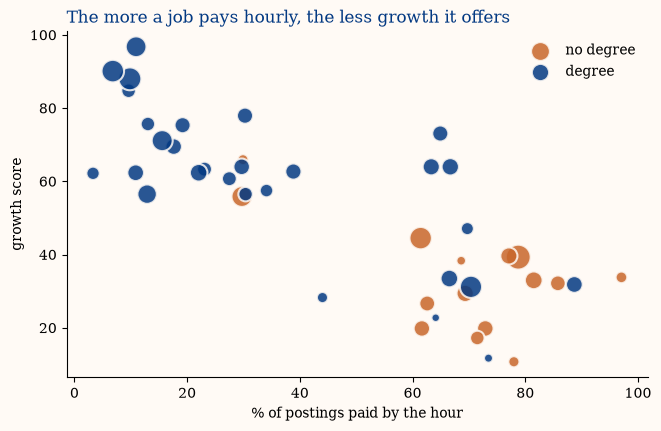

In [18]:
NO_DEGREE = {"Real Estate / Property", "Manager (general)", "Administrative / Office", "Customer Service",
             "Retail Store Manager", "Cashier / Retail Associate", "Barista", "Cook / Kitchen",
             "Server / Bartender / Host", "Housekeeping / Janitorial", "Driver / Delivery", "Warehouse / Logistics",
             "Manufacturing / Production", "Security Guard", "Bank Teller / Loan Officer"}
occ["no_degree"] = occ.index.isin(NO_DEGREE)
share = occ[occ.no_degree].n_postings.sum() / occ.n_postings.sum()
avg = occ.groupby("no_degree").growth_score.mean()
print(f"No-degree occupations: {share:.0%} of postings, average score {avg[True]:.0f} vs {avg[False]:.0f}")
for a, b in [("share_hourly", "growth_score"), ("salary", "burnout_rate"), ("salary", "promotion_likelihood")]:
    rho, p = spearmanr(occ[a], occ[b])
    print(f"{a:>8} vs {b:<22} rho = {rho:+.2f}  (p = {p:.1g})")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for flag, colour, label in [(True, ORANGE, "no degree"), (False, NAVY, "degree")]:
    d = occ[occ.no_degree == flag]
    ax.scatter(d.share_hourly * 100, d.growth_score, s=np.sqrt(d.n_postings) * 3, color=colour, alpha=.85,
               edgecolor=CREAM, linewidth=1.5, label=label)
ax.set_xlabel("% of postings paid by the hour"); ax.set_ylabel("growth score")
ax.set_title("The more a job pays hourly, the less growth it offers", loc="left", color=NAVY)
ax.legend(frameon=False); plt.show()

In [19]:
test = rev.iloc[burn_te_rows].assign(y=burn_y, p=burn_p)
rows = []
for status, g in test.groupby("employee_status"):
    if len(g) >= 200 and g.y.nunique() == 2:
        rows.append({"employment type": status.replace("_", " ").lower(), "reviews": len(g),
                     "ROC-AUC": round(roc_auc_score(g.y, g.p), 3), "actual burnout": f"{g.y.mean():.1%}",
                     "predicted": f"{g.p.mean():.1%}", "gap (pts)": round((g.p.mean() - g.y.mean()) * 100, 1)})
display(pd.DataFrame(rows))

te_err = te.assign(err=np.abs(pred - actual) / actual)
te_err["wage third"] = pd.qcut(te_err.salary, 3, labels=["low", "middle", "high"])
print("Salary model median % error by wage third:")
print((te_err.groupby("wage third", observed=True).err.median() * 100).round(1).to_string())

,employment type,reviews,ROC-AUC,actual burnout,predicted,gap (pts)
0,contract,605,0.862,20.3%,22.5%,2.1
1,intern,698,0.865,6.2%,10.5%,4.3
2,part time,2313,0.813,20.0%,23.2%,3.2
3,regular,13375,0.854,27.5%,26.5%,-1.0


Salary model median % error by wage third:
wage third
low       13.8
middle    16.2
high      17.2


In [22]:
from growth_model import GrowthScoreModel, MODEL_PATH, norm_company
import numpy as np, pandas as pd
gsm = GrowthScoreModel()
m = gsm.m
print(f"{MODEL_PATH.name}: {MODEL_PATH.stat().st_size/1e6:.1f} MB")
print("sections:", list(m.keys()))
print(f"salary vocabulary: {len(m['salary_model']['title_vocab']):,} title terms, {len(m['salary_model']['desc_vocab']):,} description terms")
print(f"{len(m['occupations'])} reference occupations, {len(m['companies']):,} companies")

growth_model.json: 1.1 MB
sections: ['version', 'built_from', 'occupation_patterns', 'stop_words', 'salary_model', 'occupations', 'overall', 'reference', 'companies', 'job_types', 'states', 'components', 'shrink_k', 'metrics']
salary vocabulary: 16,677 title terms, 8,000 description terms
44 reference occupations, 1,765 companies


In [23]:
from growth_model import GrowthScoreModel, norm_company; import numpy as np, pandas as pd; gsm = GrowthScoreModel(); m = gsm.m
posting = {"job_title": "Data Analyst", "company": "Kaiser Permanente", "state": "CA", "job_type": "Full-time",
           "description": "Analyze clinical and operational data with SQL and Python; build dashboards for leadership."}

# 1. occupation from the title (same rules as Part A)
occ_name = gsm.occupation(posting["job_title"]); print("1. occupation:", occ_name)

# 2. salary: none listed, so Model 1 predicts it from the text
pay = gsm.predict_salary(posting["job_title"], posting["description"], posting["job_type"], posting["state"], occ_name)
print(f"2. predicted pay: ${pay:,.0f}")

# 3. blend the company's reviews with the occupation average
#    weight on the company = n / (n + 20): more reviews -> more trust in the company
company = m["companies"][norm_company(posting["company"])]
occ_ref = m["occupations"][occ_name]
w = company["n"] / (company["n"] + 20)
burn = w * company["burnout_rate"] + (1 - w) * occ_ref["burnout_rate"]
print(f"3. {company['name']}: {company['n']} reviews -> weight {w:.2f}; burnout {company['burnout_rate']:.1%} (company) "
      f"vs {occ_ref['burnout_rate']:.1%} (occupation) -> {burn:.1%}")

# 4. turn it into a percentile among the 44 occupations (burnout: lower is better)
ref = np.array(m["reference"]["burnout_rate"])
print(f"4. burnout percentile: better than {(ref > burn).mean():.0%} of occupations")

# 5. the full result
r = gsm.score(posting)
print(f"5. growth score = {r['growth_score']}")
pd.DataFrame({"value": r["values"], "percentile": {k: round(v * 100) for k, v in r["percentiles"].items()},
              "source": r["sources"]})

1. occupation: Data / BI Analyst
2. predicted pay: $88,226
3. Kaiser Permanente: 242 reviews -> weight 0.92; burnout 20.1% (company) vs 17.7% (occupation) -> 19.9%
4. burnout percentile: better than 91% of occupations
5. growth score = 79.4


,value,percentile,source
salary,88225.914124,45,predicted from posting text
job_openings,7.194437,31,postings for Data / BI Analyst
culture_diversity,3.800106,100,Kaiser Permanente reviews (242) blended with o...
career_opportunities,3.844907,100,Kaiser Permanente reviews (242) blended with o...
promotion_likelihood,0.599212,100,Kaiser Permanente reviews (242) blended with o...
work_life,3.682800,89,Kaiser Permanente reviews (242) blended with o...
burnout_rate,0.199215,91,Kaiser Permanente reviews (242) blended with o...
